# WESAD Feature Pipeline

This notebook performs:

- Exploratory Data Analysis (EDA)
- PCA and t-SNE (2D and 3D)
- Supervised classification + hyperparameter optimization (Optuna or RandomizedSearchCV)
- Clustering (K-Means, DBSCAN, Gaussian Mixture)
- Autoencoder-based representation learning + classification + K-Means on embeddings

Place `wesad_features_with_phase_space.csv` next to this notebook or adjust `csv_path`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline


## 1. Load data & preprocessing

- Load CSV  
- Drop non-feature / non-numeric columns  
- Drop columns with NaNs  
- Standardize features


In [2]:
csv_path = "../data/wesad_features_with_phase_space.csv"

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
display(df.head())

label_col = "label"
y = df[label_col]

# Save subject IDs for LOSO CV
if "subject" in df.columns:
    subjects = df["subject"].values
    print("Unique subjects:", np.unique(subjects))
else:
    subjects = None
    print("No 'subject' column found – LOSO CV will be skipped.")

print("\nLabel distribution:")
print(y.value_counts().sort_index())

# Drop non-numeric / non-feature columns
obj_cols = df.select_dtypes(include="object").columns.tolist()
drop_cols = [c for c in ["Unnamed: 0", "subject", label_col] if c in df.columns]
drop_cols += obj_cols

X_raw = df.drop(columns=drop_cols)
print("\nFeature count (before NaN-drop):", X_raw.shape[1])

X = X_raw.dropna(axis=1)
print("Feature count (after NaN-drop):", X.shape[1])

feature_names = X.columns

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Final feature matrix shape:", X_scaled.shape)


Shape: (1423, 116)


,Unnamed: 0,EDA_mean,EDA_std,EDA_min,EDA_max,EDA_phasic_mean,EDA_phasic_std,EDA_phasic_min,EDA_phasic_max,EDA_smna_mean,...,Resp_wavelet_energy_low_freq,Resp_wavelet_energy_mid_freq,Resp_wavelet_energy_high_freq,Resp_wavelet_entropy,Resp_wavelet_mean_coeffs,Resp_wavelet_std_coeffs,Resp_wavelet_skew_coeffs,Resp_wavelet_kurt_coeffs,subject,label
0,0,2.951374,0.153235,-309.08,429.27,2.951374,0.084604,-309.08,429.27,2.951374,...,0.0,0.0,18813.100018,6.360669,(-0.0003738574881916235+9.5084501919906e-05j),0.095867,(-36.31166085611055-44.250901951563186j),(-677.6390763712128+3335.2308034761036j),2,1
1,1,2.971346,0.083202,-392.28,554.77,2.971346,0.013430,-392.28,554.77,2.971346,...,0.0,0.0,46499.212841,5.969250,(0.0005900973803959062-3.36396219944322e-05j),0.150717,(41.741791386241346+41.75634763420609j),(-30.078438090306488+3638.965061676656j),2,1
2,2,3.285220,0.096046,-345.19,359.57,3.285220,0.005307,-345.19,359.57,3.285220,...,0.0,0.0,36852.769716,5.809680,(0.0013867477016091259-4.257931578091323e-05j),0.134166,NaN,NaN,2,1
3,3,3.312393,0.094044,-289.26,209.89,3.312393,0.001965,-289.26,209.89,3.312393,...,0.0,0.0,4759.005541,9.286960,(-0.0002522154697395032+0.00011032167031165274j),0.048216,NaN,NaN,2,1
4,4,3.512271,0.070991,-199.01,118.26,3.512271,0.002854,-199.01,118.26,3.512271,...,0.0,0.0,6351.622041,8.424078,(-0.00048462038190719077+0.00011100973844169946j),0.055702,(-33.72692825160861-24.605456683754436j),(369.5933479496858+1817.3315327933244j),2,1


Unique subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]

Label distribution:
label
1    760
2    426
3    237
Name: count, dtype: int64

Feature count (before NaN-drop): 103
Feature count (after NaN-drop): 101
Final feature matrix shape: (1423, 101)


## 2. Exploratory Data Analysis (EDA)

- Summary stats  
- Class distribution  
- Example feature histograms by class


,count,mean,std,min,25%,50%,75%,max
EDA_mean,1423.0,2.311577,1.120470,-3.397163e-01,1.590347,2.678952,3.140461,4.172109
EDA_std,1423.0,0.030197,0.062498,2.669350e-03,0.005473,0.010149,0.025809,1.224101
EDA_min,1423.0,-213.650573,210.898457,-1.617860e+03,-282.550000,-136.140000,-70.185000,-10.740000
EDA_max,1423.0,196.637526,181.640097,6.248845e+01,65.126629,132.220000,258.965000,1789.000000
EDA_phasic_mean,1423.0,2.311577,1.120470,-3.397163e-01,1.590347,2.678952,3.140461,4.172109
EDA_phasic_std,1423.0,0.032683,0.248588,5.651702e-08,0.001103,0.006036,0.024642,8.803855
EDA_phasic_min,1423.0,-213.650573,210.898457,-1.617860e+03,-282.550000,-136.140000,-70.185000,-10.740000
EDA_phasic_max,1423.0,196.637526,181.640097,6.248845e+01,65.126629,132.220000,258.965000,1789.000000
EDA_smna_mean,1423.0,2.311577,1.120470,-3.397163e-01,1.590347,2.678952,3.140461,4.172109
EDA_smna_std,1423.0,0.282850,1.398754,6.328098e-08,0.014730,0.071852,0.288539,47.237262


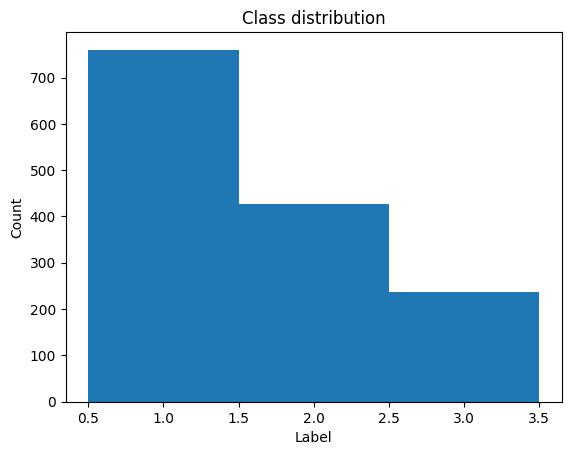

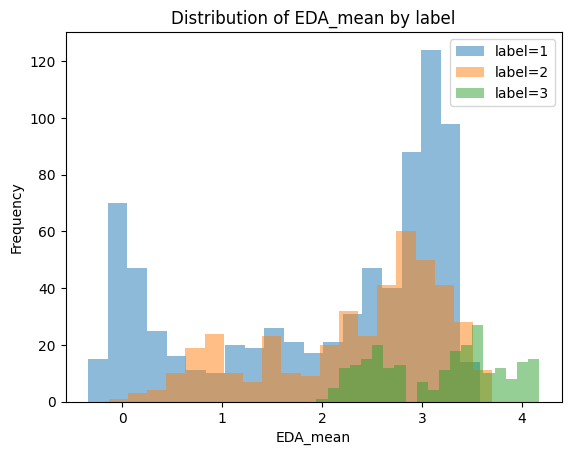

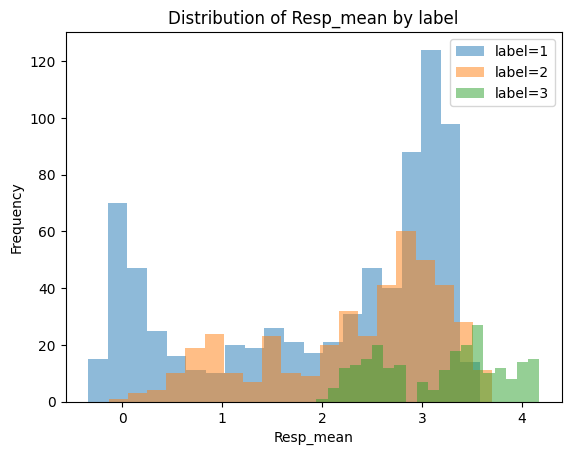

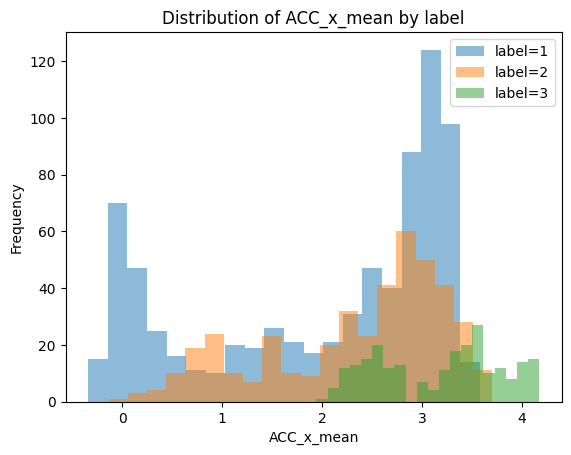

In [3]:
display(X.describe().T.head(20))

# Class distribution
fig, ax = plt.subplots()
ax.hist(y, bins=np.arange(y.min(), y.max() + 2) - 0.5)
ax.set_xlabel("Label")
ax.set_ylabel("Count")
ax.set_title("Class distribution")
plt.show()

# Some representative features (if present)
candidate_features = [f for f in ["EDA_mean", "EMG_mean", "Resp_mean", "ACC_x_mean"] if f in X.columns]

for feat in candidate_features:
    plt.figure()
    for lab in sorted(y.unique()):
        mask = y == lab
        plt.hist(X[feat][mask], bins=20, alpha=0.5, label=f"label={lab}")
    plt.xlabel(feat)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {feat} by label")
    plt.legend()
    plt.show()


## 3. PCA

- Explained variance  
- 2D scatter on first two PCs


First 10 explained variance ratios:
[0.28756035 0.12247107 0.11134578 0.06164143 0.0520506  0.04241076
 0.03428073 0.02894209 0.02280935 0.02088372]

Cumulative explained variance (first 10 components):
[0.28756035 0.41003143 0.5213772  0.58301863 0.63506923 0.67747999
 0.71176073 0.74070282 0.76351217 0.78439589]


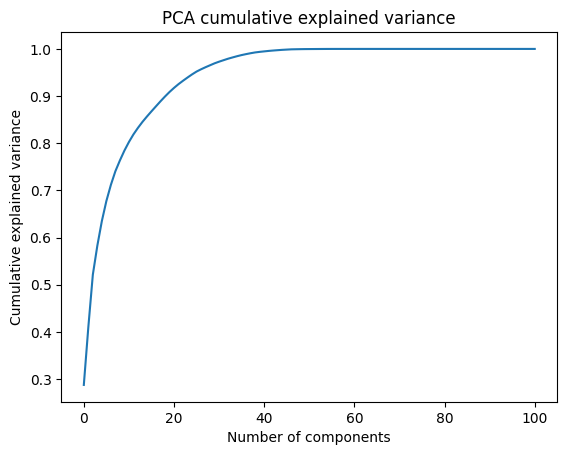

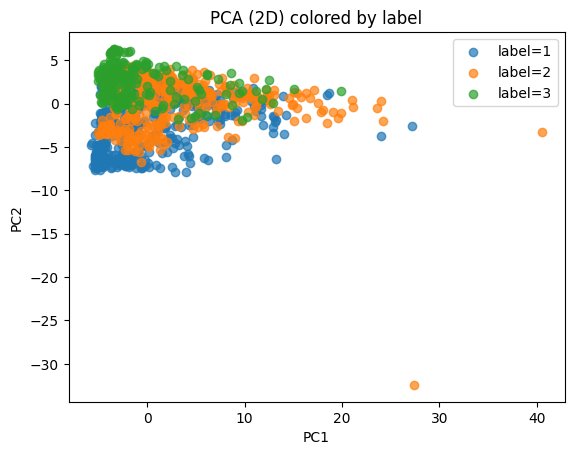

In [4]:
pca_full = PCA()
pca_full.fit(X_scaled)

expl_var_ratio = pca_full.explained_variance_ratio_
cum_expl_var = np.cumsum(expl_var_ratio)

print("First 10 explained variance ratios:")
print(expl_var_ratio[:10])
print("\nCumulative explained variance (first 10 components):")
print(cum_expl_var[:10])

plt.figure()
plt.plot(cum_expl_var)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance")
plt.show()

pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

plt.figure()
for lab in sorted(y.unique()):
    mask = y == lab
    plt.scatter(X_pca2[mask, 0], X_pca2[mask, 1], label=f"label={lab}", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA (2D) colored by label")
plt.legend()
plt.show()


## 4. t-SNE (2D & 3D)

- PCA → 30D for speed  
- 2D t-SNE on full data  
- 3D t-SNE on a subset


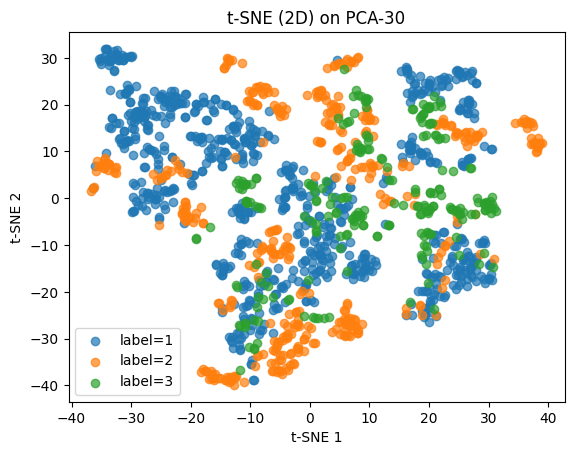

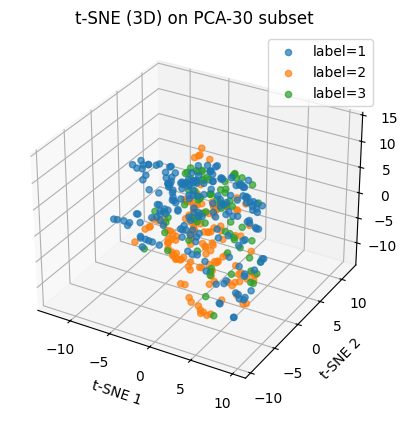

In [5]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# PCA to 30 dimensions for speed
pca_30 = PCA(n_components=min(30, X_scaled.shape[1]))
X_pca30 = pca_30.fit_transform(X_scaled)

# 2D t-SNE
tsne2 = TSNE(
    n_components=2,
    random_state=42,
    perplexity=20,
    max_iter=500,
    learning_rate="auto",
    init="random",
)
X_tsne2 = tsne2.fit_transform(X_pca30)

plt.figure()
for lab in sorted(y.unique()):
    mask = y == lab
    plt.scatter(X_tsne2[mask, 0], X_tsne2[mask, 1], label=f"label={lab}", alpha=0.7)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE (2D) on PCA-30")
plt.legend()
plt.show()

# 3D t-SNE on subset for speed
subset_size = min(400, X_pca30.shape[0])
rng = np.random.RandomState(42)
subset_idx = rng.choice(X_pca30.shape[0], size=subset_size, replace=False)
X_subset = X_pca30[subset_idx]
y_subset = y.iloc[subset_idx].reset_index(drop=True)

tsne3 = TSNE(
    n_components=3,
    random_state=42,
    perplexity=20,
    max_iter=500,
    learning_rate="auto",
    init="random",
)
X_tsne3 = tsne3.fit_transform(X_subset)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
for lab in sorted(y_subset.unique()):
    mask = y_subset == lab
    ax.scatter(X_tsne3[mask, 0], X_tsne3[mask, 1], X_tsne3[mask, 2], label=f"label={lab}", alpha=0.7)
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_zlabel("t-SNE 3")
ax.set_title("t-SNE (3D) on PCA-30 subset")
ax.legend()
plt.show()


## 5. Supervised classification

Models:
- Logistic Regression (multinomial)
- SVC
- Random Forest


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, multi_class="multinomial"),
    "SVC": SVC(),
    "RandomForest": RandomForestClassifier(random_state=42),
}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n{name} accuracy: {acc:.3f}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))



LogisticRegression accuracy: 0.828
Confusion matrix:
[[135   8   9]
 [  9  71   5]
 [ 11   7  30]]

SVC accuracy: 0.884
Confusion matrix:
[[142   6   4]
 [  3  79   3]
 [ 15   2  31]]

RandomForest accuracy: 0.923
Confusion matrix:
[[145   6   1]
 [  4  81   0]
 [ 10   1  37]]


## 6. Hyperparameter optimization (Random Forest)

Uses Optuna if available, otherwise falls back to RandomizedSearchCV.


In [7]:
try:
    import optuna
    has_optuna = True
except ImportError:
    has_optuna = False
    print("Optuna not installed; using RandomizedSearchCV instead.")

if has_optuna:
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500),
            "max_depth": trial.suggest_int("max_depth", 3, 30),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 4),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
            "random_state": 42,
            "n_jobs": -1,
        }
        rf = RandomForestClassifier(**params)
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
        scores = []
        for tr_idx, val_idx in cv.split(X_train, y_train):
            X_tr, X_val = X_train[tr_idx], X_train[val_idx]
            y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            rf.fit(X_tr, y_tr)
            y_val_pred = rf.predict(X_val)
            scores.append(accuracy_score(y_val, y_val_pred))
        return np.mean(scores)

    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=30)

    print("Best Optuna params:")
    print(study.best_trial.params)

    best_rf = RandomForestClassifier(
        **study.best_trial.params,
        random_state=42,
        n_jobs=-1,
    )
    best_rf.fit(X_train, y_train)
    y_pred_best = best_rf.predict(X_test)
    print("\nTuned RandomForest accuracy (Optuna):", accuracy_score(y_test, y_pred_best))
    print(classification_report(y_test, y_pred_best))

else:
    from sklearn.model_selection import RandomizedSearchCV

    rf = RandomForestClassifier(random_state=42)
    param_dist = {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2"],
    }

    search = RandomizedSearchCV(
        rf,
        param_distributions=param_dist,
        n_iter=20,
        cv=3,
        scoring="accuracy",
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )
    search.fit(X_train, y_train)
    print("Best params from RandomizedSearchCV:")
    print(search.best_params_)

    best_rf = search.best_estimator_
    y_pred_best = best_rf.predict(X_test)
    print("\nTuned RandomForest accuracy:", accuracy_score(y_test, y_pred_best))
    print(classification_report(y_test, y_pred_best))


[I 2025-11-18 12:12:01,384] A new study created in memory with name: no-name-62ebfd09-ab71-4811-8fdf-e7c1979fb2d4
[I 2025-11-18 12:12:02,816] Trial 0 finished with value: 0.9033398139147341 and parameters: {'n_estimators': 267, 'max_depth': 18, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.9033398139147341.
[I 2025-11-18 12:12:04,507] Trial 1 finished with value: 0.9156482895894089 and parameters: {'n_estimators': 310, 'max_depth': 29, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.9156482895894089.
[I 2025-11-18 12:12:06,010] Trial 2 finished with value: 0.9077350368004443 and parameters: {'n_estimators': 290, 'max_depth': 11, 'min_samples_split': 8, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 1 with value: 0.9156482895894089.
[I 2025-11-18 12:12:07,831] Trial 3 finished with value: 0.9068555293246309 and parameters: {'n_estimators': 343, 'max_depth': 26, 'm

Best Optuna params:
{'n_estimators': 194, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'}

Tuned RandomForest accuracy (Optuna): 0.9263157894736842
              precision    recall  f1-score   support

           1       0.92      0.95      0.94       152
           2       0.92      0.95      0.94        85
           3       0.97      0.79      0.87        48

    accuracy                           0.93       285
   macro avg       0.94      0.90      0.92       285
weighted avg       0.93      0.93      0.93       285



## 7. Clustering

Algorithms:
- K-Means
- Gaussian Mixture
- DBSCAN


In [8]:
def clustering_metrics(name, labels_true, labels_pred, X_data):
    unique_labels = np.unique(labels_pred)
    if len(unique_labels) <= 1 or len(unique_labels) >= len(X_data):
        sil = np.nan
    else:
        try:
            sil = silhouette_score(X_data, labels_pred)
        except ValueError:
            sil = np.nan
    ari = adjusted_rand_score(labels_true, labels_pred)
    nmi = normalized_mutual_info_score(labels_true, labels_pred)
    print(f"{name}: ARI={ari:.3f}, NMI={nmi:.3f}, Silhouette={sil:.3f}")

n_clusters = len(np.unique(y))

# K-Means
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
clustering_metrics("KMeans", y, kmeans_labels, X_scaled)

# Gaussian Mixture
gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)
clustering_metrics("GaussianMixture", y, gmm_labels, X_scaled)

# DBSCAN
dbscan = DBSCAN(eps=2.0, min_samples=10)
db_labels = dbscan.fit_predict(X_scaled)
clustering_metrics("DBSCAN", y, db_labels, X_scaled)


KMeans: ARI=0.019, NMI=0.090, Silhouette=0.166
GaussianMixture: ARI=0.069, NMI=0.054, Silhouette=0.079
DBSCAN: ARI=0.000, NMI=0.000, Silhouette=nan


## 8. Autoencoder + classification + K-Means on embeddings

This section uses PyTorch.

- Train autoencoder
- Freeze encoder and add classification head
- Evaluate classifier
- Apply K-Means on learned embeddings


In [9]:
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader, random_split
    has_torch = True
except ImportError:
    has_torch = False
    print("PyTorch not installed. Install with `pip install torch` to run this section.")

if has_torch:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Using device:", device)

    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y.values, dtype=torch.long)

    dataset = TensorDataset(X_tensor, y_tensor)
    n_total = len(dataset)
    n_train = int(0.7 * n_total)
    n_val = int(0.15 * n_total)
    n_test = n_total - n_train - n_val

    train_ds, val_ds, test_ds = random_split(
        dataset,
        [n_train, n_val, n_test],
        generator=torch.Generator().manual_seed(42),
    )

    batch_size = 32
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size)
    test_loader = DataLoader(test_ds, batch_size=batch_size)

    input_dim = X_scaled.shape[1]
    latent_dim = 10

    class Autoencoder(nn.Module):
        def __init__(self, input_dim, latent_dim):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 64),
                nn.ReLU(),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Linear(32, latent_dim),
            )
            self.decoder = nn.Sequential(
                nn.Linear(latent_dim, 32),
                nn.ReLU(),
                nn.Linear(32, 64),
                nn.ReLU(),
                nn.Linear(64, input_dim),
            )

        def forward(self, x):
            z = self.encoder(x)
            x_rec = self.decoder(z)
            return x_rec, z

    ae = Autoencoder(input_dim, latent_dim).to(device)
    ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
    ae_loss_fn = nn.MSELoss()

    n_epochs = 30
    for epoch in range(1, n_epochs + 1):
        ae.train()
        train_loss = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            ae_optimizer.zero_grad()
            xb_rec, _ = ae(xb)
            loss = ae_loss_fn(xb_rec, xb)
            loss.backward()
            ae_optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        ae.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, _ in val_loader:
                xb = xb.to(device)
                xb_rec, _ = ae(xb)
                loss = ae_loss_fn(xb_rec, xb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= len(val_loader.dataset)

        if epoch % 5 == 0 or epoch == 1:
            print(f"AE Epoch {epoch:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")

    # Test reconstruction loss
    ae.eval()
    test_loss = 0.0
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(device)
            xb_rec, _ = ae(xb)
            loss = ae_loss_fn(xb_rec, xb)
            test_loss += loss.item() * xb.size(0)
    test_loss /= len(test_loader.dataset)
    print("Autoencoder test reconstruction loss (MSE):", test_loss)

    # Freeze encoder
    for p in ae.encoder.parameters():
        p.requires_grad = False

    class AEClassifier(nn.Module):
        def __init__(self, encoder, latent_dim, num_classes):
            super().__init__()
            self.encoder = encoder
            self.fc = nn.Sequential(
                nn.Linear(latent_dim, 32),
                nn.ReLU(),
                nn.Linear(32, num_classes),
            )

        def forward(self, x):
            z = self.encoder(x)
            logits = self.fc(z)
            return logits

    num_classes = len(torch.unique(y_tensor))
    classifier = AEClassifier(ae.encoder, latent_dim, num_classes).to(device)

    clf_optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, classifier.parameters()),
        lr=1e-3,
    )
    clf_loss_fn = nn.CrossEntropyLoss()

    n_epochs_clf = 30
    for epoch in range(1, n_epochs_clf + 1):
        classifier.train()
        train_loss = 0.0
        train_correct = 0
        n_train_samples = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            clf_optimizer.zero_grad()
            logits = classifier(xb)
            loss = clf_loss_fn(logits, yb)
            loss.backward()
            clf_optimizer.step()
            train_loss += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == yb).sum().item()
            n_train_samples += xb.size(0)
        train_loss /= n_train_samples
        train_acc = train_correct / n_train_samples

        classifier.eval()
        val_loss = 0.0
        val_correct = 0
        n_val_samples = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = classifier(xb)
                loss = clf_loss_fn(logits, yb)
                val_loss += loss.item() * xb.size(0)
                preds = logits.argmax(dim=1)
                val_correct += (preds == yb).sum().item()
                n_val_samples += xb.size(0)
        val_loss /= n_val_samples
        val_acc = val_correct / n_val_samples

        if epoch % 5 == 0 or epoch == 1:
            print(
                f"AE-Classifier Epoch {epoch:02d}: "
                f"train_loss={train_loss:.4f}, train_acc={train_acc:.3f}, "
                f"val_loss={val_loss:.4f}, val_acc={val_acc:.3f}"
            )

    # Test accuracy
    classifier.eval()
    test_correct = 0
    n_test_samples = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = classifier(xb)
            preds = logits.argmax(dim=1)
            test_correct += (preds == yb).sum().item()
            n_test_samples += xb.size(0)
    test_acc = test_correct / n_test_samples
    print("AE-based classifier test accuracy:", test_acc)

    # K-Means on embeddings
    ae.eval()
    with torch.no_grad():
        embeddings = ae.encoder(X_tensor.to(device))
    embeddings_np = embeddings.cpu().numpy()

    kmeans_ae = KMeans(n_clusters=len(np.unique(y)), random_state=42, n_init=10)
    kmeans_ae_labels = kmeans_ae.fit_predict(embeddings_np)
    clustering_metrics("KMeans (AE embeddings)", y, kmeans_ae_labels, embeddings_np)


Using device: cuda
AE Epoch 01: train_loss=0.7866, val_loss=1.3342
AE Epoch 05: train_loss=0.3951, val_loss=1.0205
AE Epoch 10: train_loss=0.3014, val_loss=0.9477
AE Epoch 15: train_loss=0.2513, val_loss=0.8957
AE Epoch 20: train_loss=0.2249, val_loss=0.8562
AE Epoch 25: train_loss=0.2077, val_loss=0.8295
AE Epoch 30: train_loss=0.1904, val_loss=0.8260
Autoencoder test reconstruction loss (MSE): 0.22684408919276478


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


## 9. One-Subject-Out (Leave-One-Subject-Out) cross validation

In this section we evaluate a classifier with a leave-one-subject-out strategy:

- For each subject in the dataset:
  - Train on all other subjects
  - Test on that one subject
- Aggregate predictions across all folds to compute:
  - Per-subject accuracy
  - Overall accuracy
  - Classification report
  - Confusion matrix


In [ ]:
from sklearn.base import clone

if subjects is None:
    print("Cannot run One-Subject-Out CV: 'subject' column not present.")
else:
    unique_subjects = np.unique(subjects)
    print("Running One-Subject-Out CV over subjects:", unique_subjects)
    
    # You can swap this for best_rf if you want to use tuned RF:
    # base_model = best_rf
    base_model = RandomForestClassifier(
        random_state=42,
        n_estimators=499,
        max_depth=27,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features='log2'
    )
    
    all_true = []
    all_pred = []
    per_subject_acc = []
    
    for subj in unique_subjects:
        test_mask = (subjects == subj)
        X_train_subj = X_scaled[~test_mask]
        X_test_subj = X_scaled[test_mask]
        y_train_subj = y[~test_mask]
        y_test_subj = y[test_mask]
        
        if X_test_subj.shape[0] == 0:
            print(f"Subject {subj} has no samples, skipping.")
            continue
        
        model = clone(base_model)
        model.fit(X_train_subj, y_train_subj)
        y_pred_subj = model.predict(X_test_subj)
        
        acc_subj = accuracy_score(y_test_subj, y_pred_subj)
        per_subject_acc.append((subj, acc_subj))
        
        all_true.extend(list(y_test_subj))
        all_pred.extend(list(y_pred_subj))
    
    all_true = np.array(all_true)
    all_pred = np.array(all_pred)
    
    print("\nPer-subject accuracies:")
    for subj, acc_subj in per_subject_acc:
        print(f"  Subject {subj}: {acc_subj:.3f}")
    
    overall_acc = accuracy_score(all_true, all_pred)
    print("\nOverall One-Subject-Out accuracy:", overall_acc)
    
    print("\nClassification report (aggregated over all LOSO folds):")
    print(classification_report(all_true, all_pred))
    
    print("Confusion matrix (aggregated):")
    print(confusion_matrix(all_true, all_pred))


Running One-Subject-Out CV over subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]

Per-subject accuracies:
  Subject 2: 0.724
  Subject 3: 0.675
  Subject 4: 0.829
  Subject 5: 0.949
  Subject 6: 0.744
  Subject 7: 0.949
  Subject 8: 0.886
  Subject 9: 0.885
  Subject 10: 0.617
  Subject 11: 0.848
  Subject 13: 0.886
  Subject 14: 0.709
  Subject 15: 0.595
  Subject 16: 0.823
  Subject 17: 0.691

Overall One-Subject-Out accuracy: 0.7869269949066214

Classification report (aggregated over all LOSO folds):
              precision    recall  f1-score   support

           0       0.63      0.48      0.54       195
           1       0.81      0.89      0.85       628
           2       0.81      0.77      0.79       355

    accuracy                           0.79      1178
   macro avg       0.75      0.71      0.73      1178
weighted avg       0.78      0.79      0.78      1178

Confusion matrix (aggregated):
[[ 93  72  30]
 [ 31 562  35]
 [ 23  60 272]]


## 10. MLP classifier with hyperparameter optimization

In this section we:

- Train a Multi-Layer Perceptron (MLP) classifier on the standardized features.
- Use cross-validation to tune its hyperparameters (Optuna if available, otherwise RandomizedSearchCV).
- Evaluate the best MLP on the held-out test set.


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

try:
    import optuna
    has_optuna_mlp = True
except ImportError:
    has_optuna_mlp = False
    print("Optuna not installed; MLP will be tuned with RandomizedSearchCV instead.")

print("MLP optimization – using Optuna:", has_optuna_mlp)

if has_optuna_mlp:
    def mlp_objective(trial):
        hidden_layers = trial.suggest_categorical(
            "hidden_layer_sizes",
            [(64,), (128,), (64, 32), (128, 64)]
        )
        alpha = trial.suggest_loguniform("alpha", 1e-5, 1e-1)
        lr_init = trial.suggest_loguniform("learning_rate_init", 1e-4, 1e-2)
        activation = trial.suggest_categorical("activation", ["relu", "tanh"])
        batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])
        
        mlp = MLPClassifier(
            hidden_layer_sizes=hidden_layers,
            alpha=alpha,
            learning_rate_init=lr_init,
            activation=activation,
            batch_size=batch_size,
            max_iter=300,
            random_state=42,
        )
        
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
        scores = []
        for tr_idx, val_idx in cv.split(X_train, y_train):
            X_tr, X_val = X_train[tr_idx], X_train[val_idx]
            y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            mlp.fit(X_tr, y_tr)
            y_val_pred = mlp.predict(X_val)
            scores.append(accuracy_score(y_val, y_val_pred))
        return float(np.mean(scores))
    
    mlp_study = optuna.create_study(direction="maximize")
    mlp_study.optimize(mlp_objective, n_trials=30)
    
    print("Best MLP params (Optuna):")
    print(mlp_study.best_trial.params)
    
    best_mlp = MLPClassifier(
        hidden_layer_sizes=mlp_study.best_trial.params["hidden_layer_sizes"],
        alpha=mlp_study.best_trial.params["alpha"],
        learning_rate_init=mlp_study.best_trial.params["learning_rate_init"],
        activation=mlp_study.best_trial.params["activation"],
        batch_size=mlp_study.best_trial.params["batch_size"],
        max_iter=300,
        random_state=42,
    )
    best_mlp.fit(X_train, y_train)

else:
    from sklearn.model_selection import RandomizedSearchCV
    
    base_mlp = MLPClassifier(
        max_iter=300,
        random_state=42,
    )
    
    param_dist_mlp = {
        "hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
        "alpha": [1e-5, 1e-4, 1e-3, 1e-2],
        "learning_rate_init": [1e-4, 5e-4, 1e-3, 5e-3],
        "activation": ["relu", "tanh"],
        "batch_size": [32, 64, 128],
    }
    
    mlp_search = RandomizedSearchCV(
        base_mlp,
        param_distributions=param_dist_mlp,
        n_iter=20,
        cv=3,
        scoring="accuracy",
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )
    mlp_search.fit(X_train, y_train)
    
    print("Best MLP params (RandomizedSearchCV):")
    print(mlp_search.best_params_)
    
    best_mlp = mlp_search.best_estimator_

# Evaluate best MLP
y_pred_mlp = best_mlp.predict(X_test)
mlp_acc = accuracy_score(y_test, y_pred_mlp)
print("\nBest MLP test accuracy:", mlp_acc)
print("\nMLP classification report:")
print(classification_report(y_test, y_pred_mlp))
print("MLP confusion matrix:")
print(confusion_matrix(y_test, y_pred_mlp))


[I 2025-11-14 02:56:08,994] A new study created in memory with name: no-name-01b181c2-dcc7-45a2-afbc-aeaa38235615


MLP optimization – using Optuna: True


[I 2025-11-14 02:56:26,003] Trial 0 finished with value: 0.9012738853503185 and parameters: {'hidden_layer_sizes': (128,), 'alpha': 0.005177102165786408, 'learning_rate_init': 0.002800017598167071, 'activation': 'tanh', 'batch_size': 32}. Best is trial 0 with value: 0.9012738853503185.
[I 2025-11-14 02:56:58,556] Trial 1 finished with value: 0.8895966029723992 and parameters: {'hidden_layer_sizes': (128, 64), 'alpha': 0.00018725840436905486, 'learning_rate_init': 0.00020115771171322371, 'activation': 'tanh', 'batch_size': 32}. Best is trial 0 with value: 0.9012738853503185.
[I 2025-11-14 02:57:15,436] Trial 2 finished with value: 0.8789808917197454 and parameters: {'hidden_layer_sizes': (128,), 'alpha': 8.118516881001768e-05, 'learning_rate_init': 0.000237660921192269, 'activation': 'tanh', 'batch_size': 128}. Best is trial 0 with value: 0.9012738853503185.
[I 2025-11-14 02:57:30,499] Trial 3 finished with value: 0.9033970276008493 and parameters: {'hidden_layer_sizes': (128,), 'alpha'

Best MLP params (Optuna):
{'hidden_layer_sizes': (64,), 'alpha': 1.1141481818097138e-05, 'learning_rate_init': 0.0005271658323921947, 'activation': 'relu', 'batch_size': 64}

Best MLP test accuracy: 0.9364406779661016

MLP classification report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86        39
           1       0.95      0.97      0.96       126
           2       0.96      0.93      0.94        71

    accuracy                           0.94       236
   macro avg       0.92      0.91      0.92       236
weighted avg       0.94      0.94      0.94       236

MLP confusion matrix:
[[ 33   5   1]
 [  2 122   2]
 [  3   2  66]]
